# Exploratory Data Analysis (EDA) - Titanic Dataset


## 1. Setup and data loading

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})

OUT_PAL = {"Died": "#d65f5f", "Survived": "#4c9f70"}   # consistent colours for the outcome

def save(name):
    plt.savefig(f"figures/{name}.png")
    plt.show()

In [2]:
df = pd.read_csv("data/titanic.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Data understanding
Structure, summary statistics and category counts.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.00,257.35,1.00,223.50,446.00,668.5,891.00
Survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
Pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
Age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33


In [5]:
df.describe(exclude="number").T

,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


In [6]:
for col in ["Survived", "Pclass", "Sex", "Embarked", "SibSp", "Parch"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).to_string(), "\n")

--- Survived ---
Survived
0    549
1    342 

--- Pclass ---
Pclass
3    491
1    216
2    184 

--- Sex ---
Sex
male      577
female    314 

--- Embarked ---
Embarked
S      644
C      168
Q       77
NaN      2 

--- SibSp ---
SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5 

--- Parch ---
Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1 



### 2.1 Missing values

,missing,pct
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


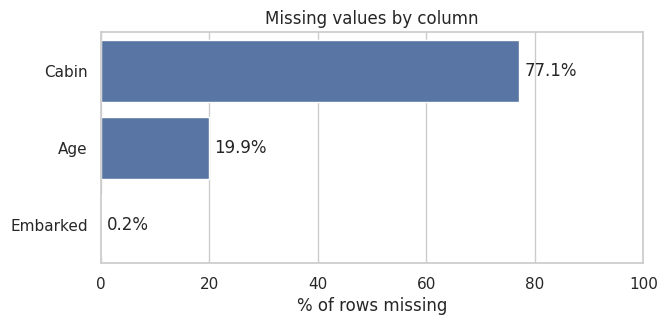

In [7]:
missing = (df.isna().sum().to_frame("missing")
             .assign(pct=lambda d: (d["missing"] / len(df) * 100).round(1))
             .query("missing > 0").sort_values("missing", ascending=False))
display(missing)

fig, ax = plt.subplots(figsize=(7, 3))
sns.barplot(x=missing["pct"], y=missing.index, color="#4c72b0", ax=ax)
for i, v in enumerate(missing["pct"]):
    ax.text(v + 1, i, f"{v}%", va="center")
ax.set_xlim(0, 100); ax.set_xlabel("% of rows missing"); ax.set_ylabel("")
ax.set_title("Missing values by column")
save("01_missing_values")

In [8]:
# Is the missing Age random? Check by class and by outcome
print("Missing Age by class:\n", df[df["Age"].isna()]["Pclass"].value_counts().sort_index().to_string())
print("\nSurvival rate when Age is missing vs known:")
print(df.groupby(df["Age"].isna())["Survived"].mean().round(3).rename({False: "Age known", True: "Age missing"}).to_string())

Missing Age by class:
 Pclass
1     30
2     11
3    136

Survival rate when Age is missing vs known:
Age
Age known      0.406
Age missing    0.294


**Observations**

- **Cabin** is missing for 687 of 891 passengers (77.1%) - too sparse to fill in, so it is converted into a simple `HasCabin` flag.
- **Age** is missing for 177 passengers (19.9%). The gaps are not random: 136 of them are 3rd-class passengers, and passengers with a missing age survived less (29.4%) than those with a known age (40.6%).
- **Embarked** has only 2 missing values (0.2%); they are filled with the most frequent port (Southampton).

## 3. Cleaning and feature engineering

In [9]:
# Embarked: only 2 missing -> fill with the most frequent port
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Cabin: 77% missing -> keep only whether a cabin was recorded
df["HasCabin"] = df["Cabin"].notna().astype(int)
print("Survival by HasCabin:", df.groupby("HasCabin")["Survived"].mean().round(3).to_dict())
print("Share with cabin recorded, by class:", df.groupby("Pclass")["HasCabin"].mean().round(3).to_dict())
df = df.drop(columns="Cabin")

# New features
df["Outcome"] = df["Survived"].map({0: "Died", 1: "Survived"})
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df["Title"] = df["Title"].where(df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")

# Age groups are built from known ages only (missing stays NaN)
df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 12, 18, 35, 60, 100],
                        labels=["Child (0-12)", "Teen (13-18)", "Young adult (19-35)", "Adult (36-60)", "Senior (61+)"])

# Model-ready Age (NOT used in the EDA plots): median by Pclass and Sex
df["Age_filled"] = df["Age"].fillna(df.groupby(["Pclass", "Sex"])["Age"].transform("median"))

print("\nRemaining missing values:\n", df.isna().sum()[lambda s: s > 0].to_string())
df.to_csv("data/titanic_clean.csv", index=False)
df[["Name", "Sex", "Age", "Title", "AgeGroup", "FamilySize", "IsAlone", "HasCabin"]].head()

Survival by HasCabin: {0: 0.3, 1: 0.667}
Share with cabin recorded, by class: {1: 0.815, 2: 0.087, 3: 0.024}

Remaining missing values:
 Age         177
AgeGroup    177


,Name,Sex,Age,Title,AgeGroup,FamilySize,IsAlone,HasCabin
0,"Braund, Mr. Owen Harris",male,22.0,Mr,Young adult (19-35),2,0,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,Mrs,Adult (36-60),2,0,1
2,"Heikkinen, Miss. Laina",female,26.0,Miss,Young adult (19-35),1,1,0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,Mrs,Young adult (19-35),2,0,1
4,"Allen, Mr. William Henry",male,35.0,Mr,Young adult (19-35),1,1,0


## 4. Univariate analysis
One variable at a time: histograms, count plots and boxplots.

### 4.1 Histograms - Age and Fare

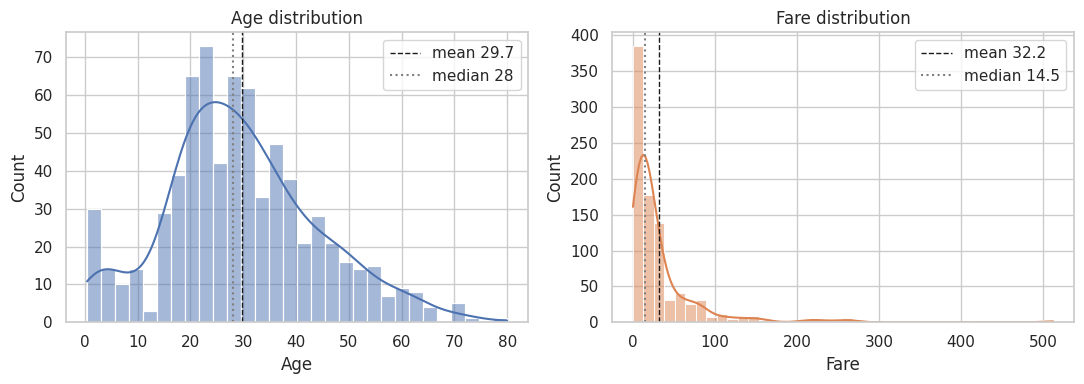

Age     0.39
Fare    4.79


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Age"].dropna(), bins=30, kde=True, color="#4c72b0", ax=axes[0])
axes[0].axvline(df["Age"].mean(), color="k", ls="--", lw=1, label=f"mean {df['Age'].mean():.1f}")
axes[0].axvline(df["Age"].median(), color="grey", ls=":", lw=1.5, label=f"median {df['Age'].median():.0f}")
axes[0].legend(); axes[0].set_title("Age distribution")

sns.histplot(df["Fare"], bins=40, kde=True, color="#dd8452", ax=axes[1])
axes[1].axvline(df["Fare"].mean(), color="k", ls="--", lw=1, label=f"mean {df['Fare'].mean():.1f}")
axes[1].axvline(df["Fare"].median(), color="grey", ls=":", lw=1.5, label=f"median {df['Fare'].median():.1f}")
axes[1].legend(); axes[1].set_title("Fare distribution")
plt.tight_layout()
save("02_age_fare_histograms")
print(df[["Age", "Fare"]].skew().round(2).rename("skewness").to_string())

### 4.2 Count plots - Survived, Pclass, Sex, Embarked

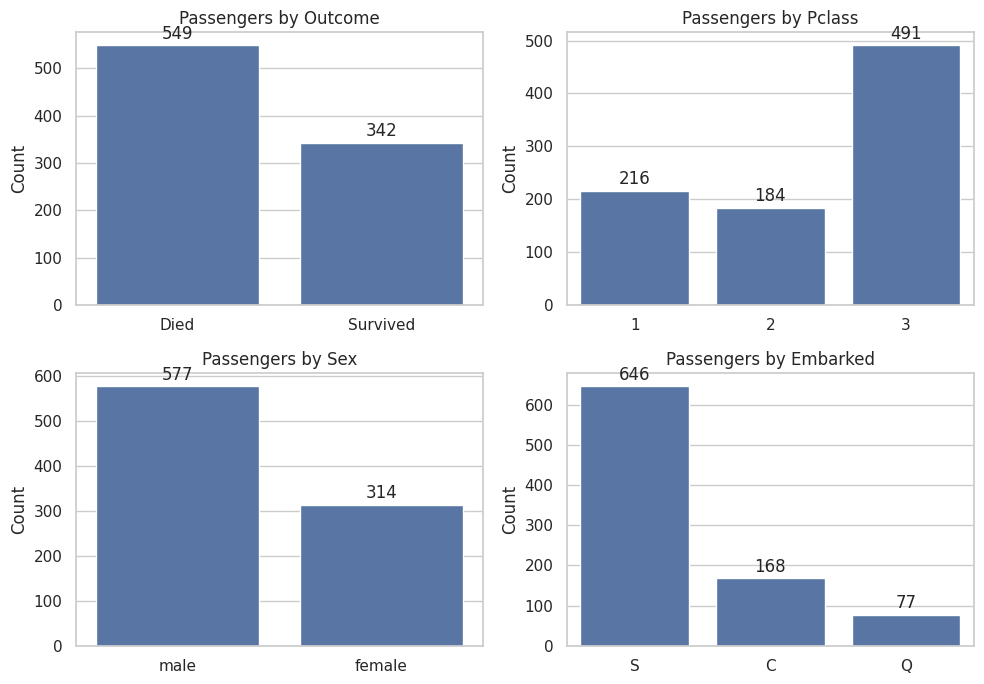

{1: 24.2, 2: 20.7, 3: 55.1}
{'S': 72.5, 'C': 18.9, 'Q': 8.6}


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (col, order) in zip(axes.flat, [("Outcome", ["Died", "Survived"]), ("Pclass", [1, 2, 3]),
                                        ("Sex", ["male", "female"]), ("Embarked", ["S", "C", "Q"])]):
    sns.countplot(data=df, x=col, order=order, color="#4c72b0", ax=ax)
    ax.bar_label(ax.containers[0], padding=2)
    ax.set_title(f"Passengers by {col}"); ax.set_ylabel("Count"); ax.set_xlabel("")
plt.tight_layout()
save("03_categorical_counts")
print((df["Pclass"].value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
print((df["Embarked"].value_counts(normalize=True) * 100).round(1).to_dict())

**Observations**

- Only **342 of 891 passengers survived (38.4%)**; 549 (61.6%) died - a moderately imbalanced target.
- 3rd class is the largest group (491 passengers, 55.1%), then 1st (216, 24.2%) and 2nd (184, 20.7%).
- Men outnumber women: 577 (64.8%) vs 314 (35.2%).
- Southampton is the main port of embarkation (646 passengers, 72.5%), followed by Cherbourg (168) and Queenstown (77).

### 4.3 Boxplots - Age and Fare (outlier check)

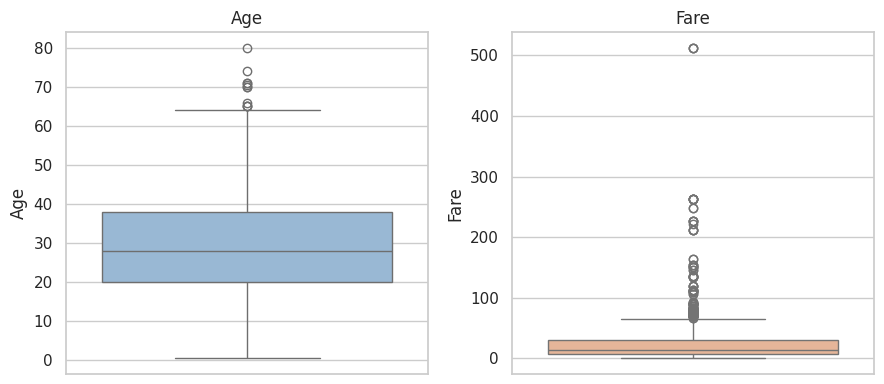

Age: 11 outliers by the 1.5*IQR rule (fences: -6.69 to 64.81)
Fare: 116 outliers by the 1.5*IQR rule (fences: -26.72 to 65.63)


In [12]:
def iqr_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((s < lo) | (s > hi)).sum()), round(lo, 2), round(hi, 2)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
sns.boxplot(y=df["Age"], color="#8fb8de", ax=axes[0]); axes[0].set_title("Age")
sns.boxplot(y=df["Fare"], color="#f2b28c", ax=axes[1]); axes[1].set_title("Fare")
plt.tight_layout()
save("04_boxplots_age_fare")
for c in ["Age", "Fare"]:
    n, lo, hi = iqr_outliers(df[c])
    print(f"{c}: {n} outliers by the 1.5*IQR rule (fences: {lo} to {hi})")

### 4.4 Handling skew - log transform of Fare

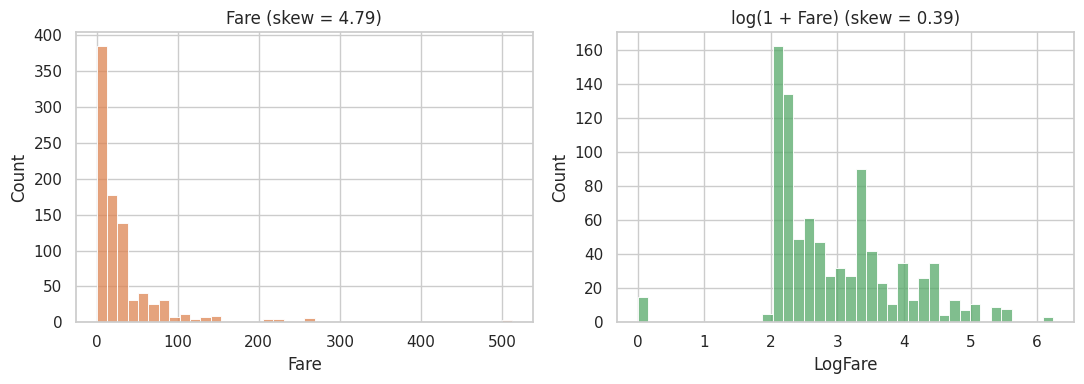

In [13]:
df["LogFare"] = np.log1p(df["Fare"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Fare"], bins=40, color="#dd8452", ax=axes[0]);  axes[0].set_title(f"Fare (skew = {df['Fare'].skew():.2f})")
sns.histplot(df["LogFare"], bins=40, color="#55a868", ax=axes[1]); axes[1].set_title(f"log(1 + Fare) (skew = {df['LogFare'].skew():.2f})")
plt.tight_layout()
save("05_fare_log_transform")

## 5. Bivariate analysis
How each feature relates to survival, and how features relate to each other.

In [14]:
def rate_plot(ax, col, title, color="#4c9f70"):
    g = df.groupby(col, observed=True)["Survived"].agg(["mean", "count"]).reset_index()
    sns.barplot(data=g, x=col, y="mean", color=color, ax=ax)
    for p, n in zip(ax.patches, g["count"]):
        ax.text(p.get_x() + p.get_width() / 2, p.get_height() + 0.015,
                f"{p.get_height():.0%}\n(n={n})", ha="center", va="bottom", fontsize=8)
    ax.axhline(df["Survived"].mean(), ls="--", color="grey", lw=1)
    ax.set_ylim(0, 1.05); ax.set_ylabel("Survival rate"); ax.set_xlabel(""); ax.set_title(title)

### 5.1 Survival rate by Sex, Pclass and Embarked

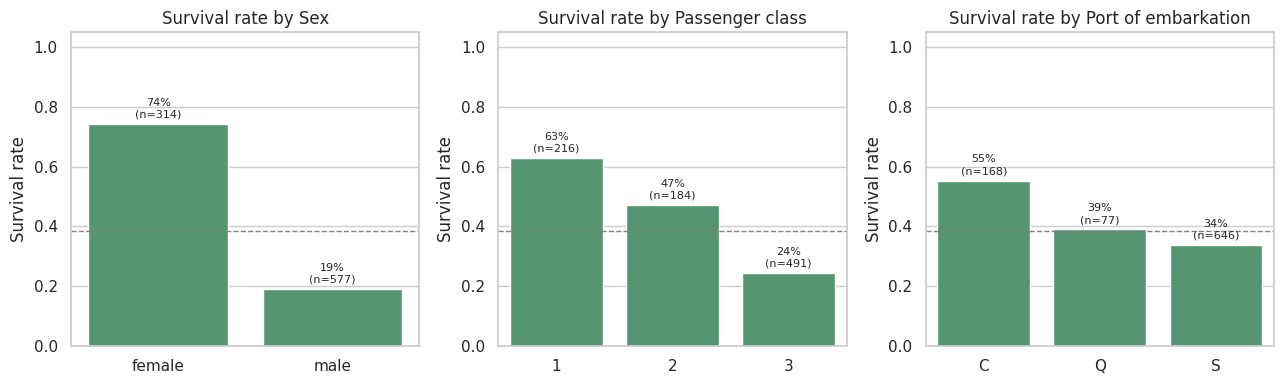

Pclass       1     2     3
Embarked                  
C         0.51  0.10  0.39
Q         0.03  0.04  0.94
S         0.20  0.25  0.55


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
rate_plot(axes[0], "Sex", "Survival rate by Sex")
rate_plot(axes[1], "Pclass", "Survival rate by Passenger class")
rate_plot(axes[2], "Embarked", "Survival rate by Port of embarkation")
plt.tight_layout()
save("06_survival_sex_class_port")
print(pd.crosstab(df["Embarked"], df["Pclass"], normalize="index").round(2))

### 5.2 Survival rate by family size

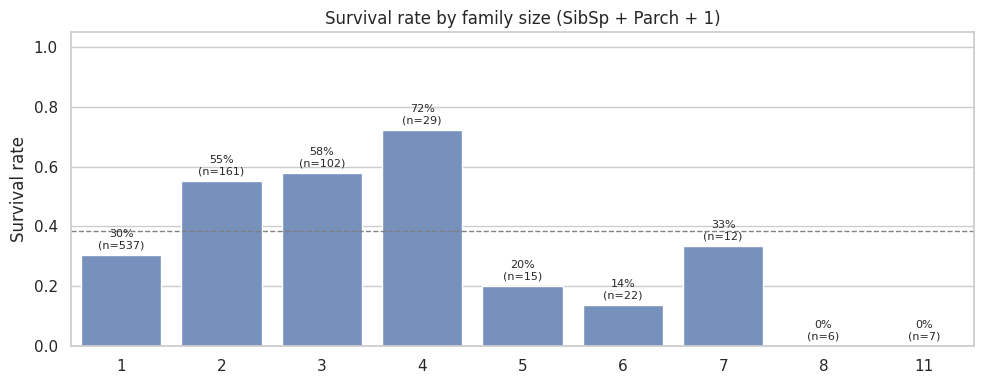

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
rate_plot(ax, "FamilySize", "Survival rate by family size (SibSp + Parch + 1)", color="#6a8fc7")
plt.tight_layout()
save("07_survival_family_size")

### 5.3 Survival rate by age group

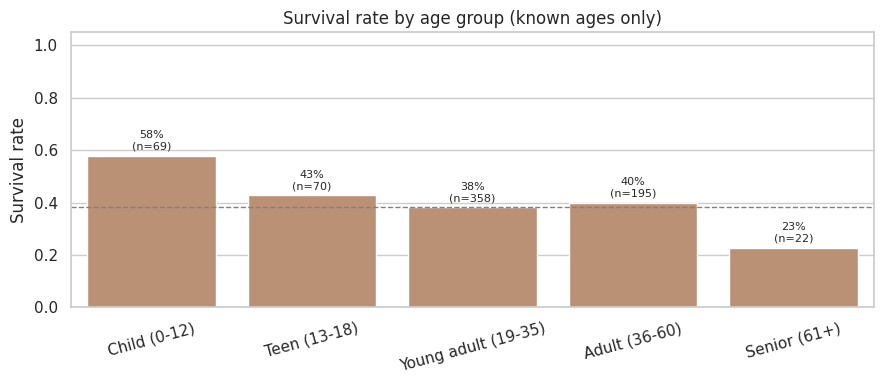

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
rate_plot(ax, "AgeGroup", "Survival rate by age group (known ages only)", color="#c78f6a")
plt.xticks(rotation=15)
plt.tight_layout()
save("08_survival_age_group")

### 5.4 Survival rate by title

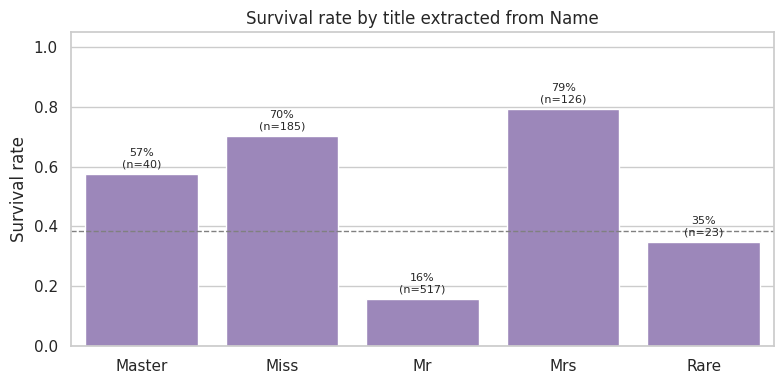

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
rate_plot(ax, "Title", "Survival rate by title extracted from Name", color="#9a7fc2")
plt.tight_layout()
save("09_survival_title")

### 5.5 Age distribution of survivors vs non-survivors

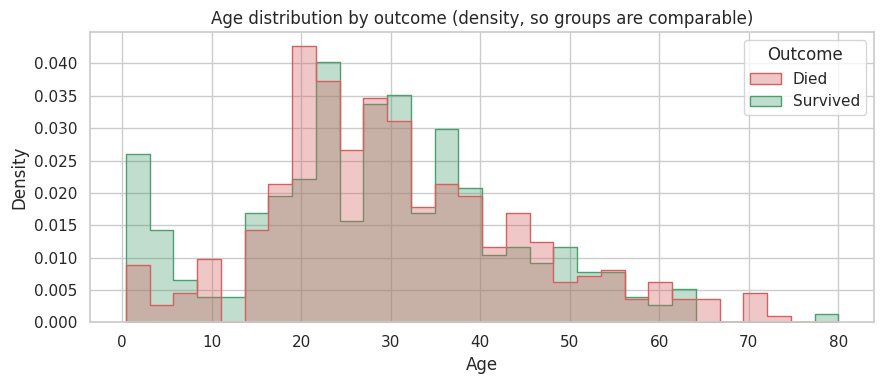

          mean  median
Outcome               
Died      30.6    28.0
Survived  28.3    28.0


In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df.dropna(subset=["Age"]), x="Age", hue="Outcome", palette=OUT_PAL, bins=30,
             stat="density", common_norm=False, element="step", alpha=0.35, ax=ax)
ax.set_title("Age distribution by outcome (density, so groups are comparable)")
plt.tight_layout()
save("10_age_by_outcome")
print(df.groupby("Outcome")["Age"].agg(["mean", "median"]).round(1))

### 5.6 Fare and Age by passenger class (boxplots)

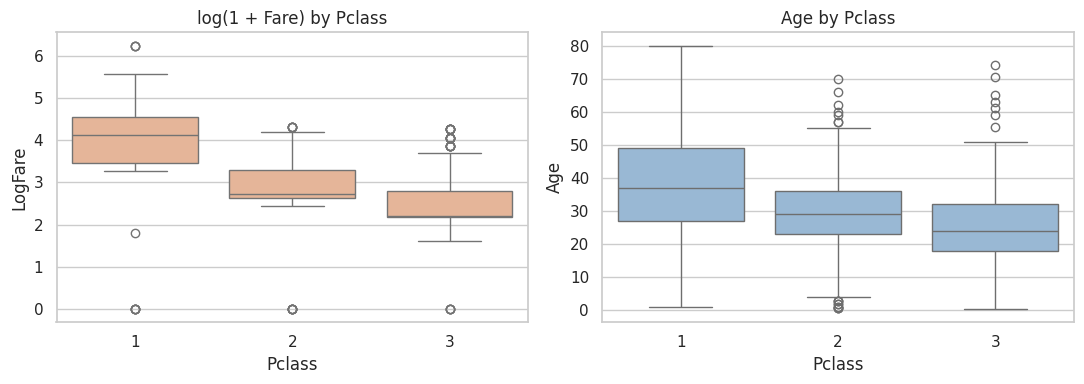

         Fare   Age
Pclass             
1       60.29  37.0
2       14.25  29.0
3        8.05  24.0


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x="Pclass", y="LogFare", color="#f2b28c", ax=axes[0]); axes[0].set_title("log(1 + Fare) by Pclass")
sns.boxplot(data=df, x="Pclass", y="Age", color="#8fb8de", ax=axes[1]); axes[1].set_title("Age by Pclass")
plt.tight_layout()
save("11_boxplots_by_class")
print(df.groupby("Pclass")[["Fare", "Age"]].median().round(2))

### 5.7 Scatterplot - Age vs Fare coloured by outcome

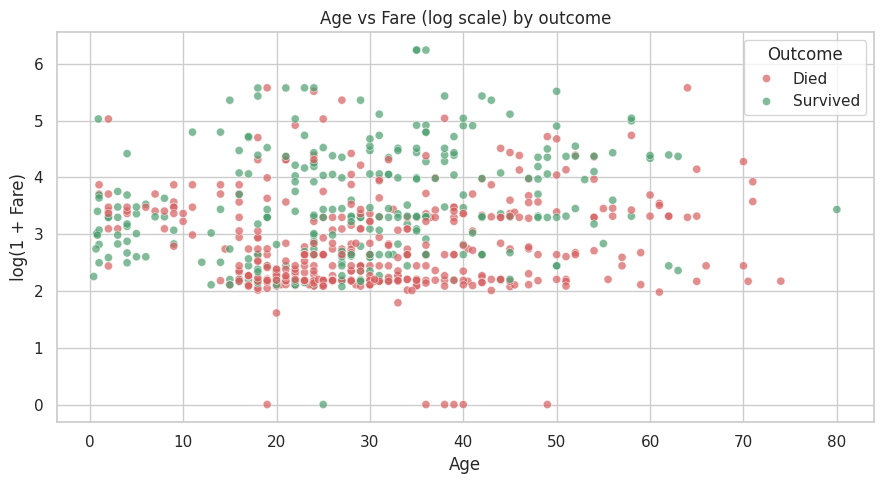

Correlation Age-Fare: 0.1

Survival rate by fare quartile:
                  mean  count
Fare                         
(-0.001, 7.91]   0.197    223
(7.91, 14.454]   0.304    224
(14.454, 31.0]   0.455    222
(31.0, 512.329]  0.581    222

Fare >= 55: 69.5% survived (n=141) | Fare < 10: 19.9% (n=336)


In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df, x="Age", y="LogFare", hue="Outcome", palette=OUT_PAL, alpha=0.7, s=35, ax=ax)
ax.set_ylabel("log(1 + Fare)"); ax.set_title("Age vs Fare (log scale) by outcome")
plt.tight_layout()
save("12_scatter_age_fare")

print("Correlation Age-Fare:", round(df["Age"].corr(df["Fare"]), 2))
print("\nSurvival rate by fare quartile:")
print(df.groupby(pd.qcut(df["Fare"], 4), observed=True)["Survived"].agg(["mean", "count"]).round(3))
big = df[df["Fare"] >= 55]["Survived"]; small = df[df["Fare"] < 10]["Survived"]
print(f"\nFare >= 55: {big.mean():.1%} survived (n={len(big)}) | Fare < 10: {small.mean():.1%} (n={len(small)})")

### 5.8 Survival by Pclass and Sex together

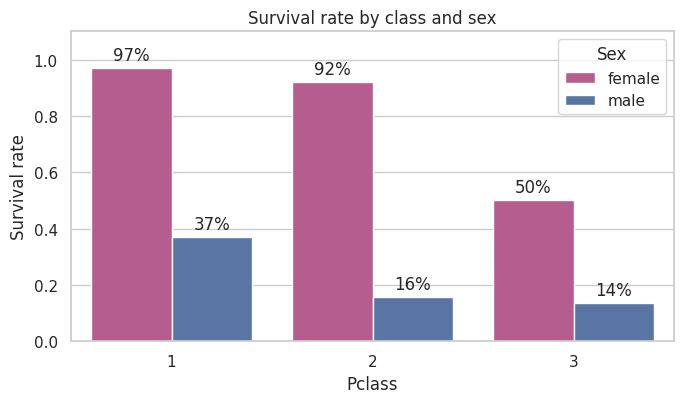

Sex     female  male
Pclass              
1           94   122
2           76   108
3          144   347


In [22]:
fig, ax = plt.subplots(figsize=(7, 4.2))
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex", errorbar=None,
            palette={"female": "#c44e8f", "male": "#4c72b0"}, ax=ax)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0%}" for v in c.datavalues], padding=3)
ax.set_ylim(0, 1.1); ax.set_ylabel("Survival rate"); ax.set_title("Survival rate by class and sex")
plt.tight_layout()
save("13_survival_class_sex")
print(pd.crosstab(df["Pclass"], df["Sex"]))

## 6. Multivariate analysis

### 6.1 Pairplot (`sns.pairplot`)

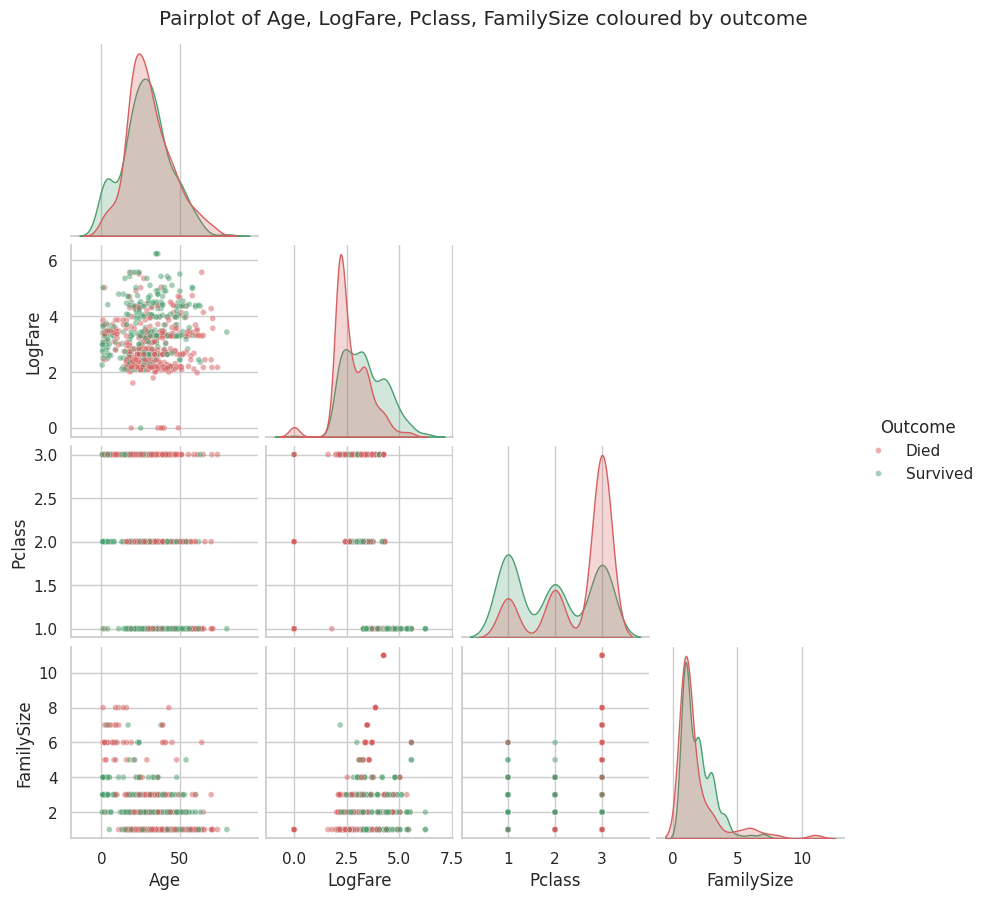

In [23]:
pp = sns.pairplot(df, vars=["Age", "LogFare", "Pclass", "FamilySize"], hue="Outcome", palette=OUT_PAL,
                  diag_kind="kde", corner=True, dropna=True, height=2.2,
                  plot_kws=dict(alpha=0.5, s=18), diag_kws=dict(common_norm=False, fill=True))
pp.figure.suptitle("Pairplot of Age, LogFare, Pclass, FamilySize coloured by outcome", y=1.02)
pp.figure.savefig("figures/14_pairplot.png")
plt.show()

### 6.2 Correlation heatmap (`sns.heatmap`)

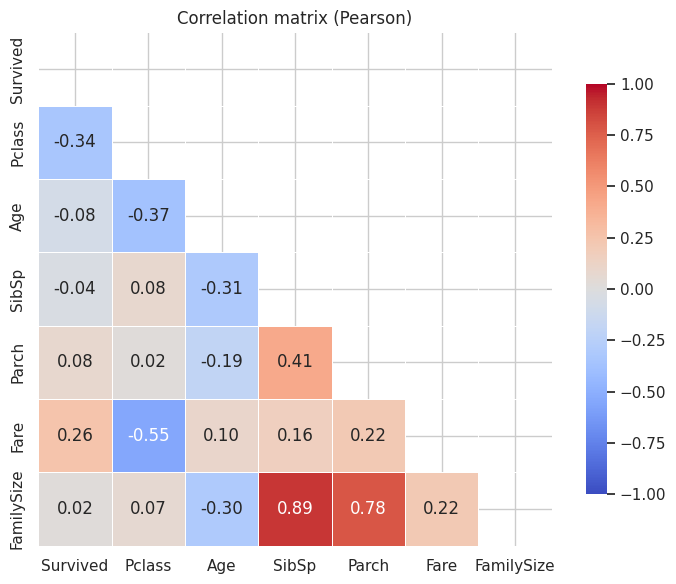

In [24]:
num_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize"]
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation matrix (Pearson)")
plt.tight_layout()
save("15_correlation_heatmap")

### 6.3 Survival-rate heatmaps (Pclass x Sex and Pclass x AgeGroup)

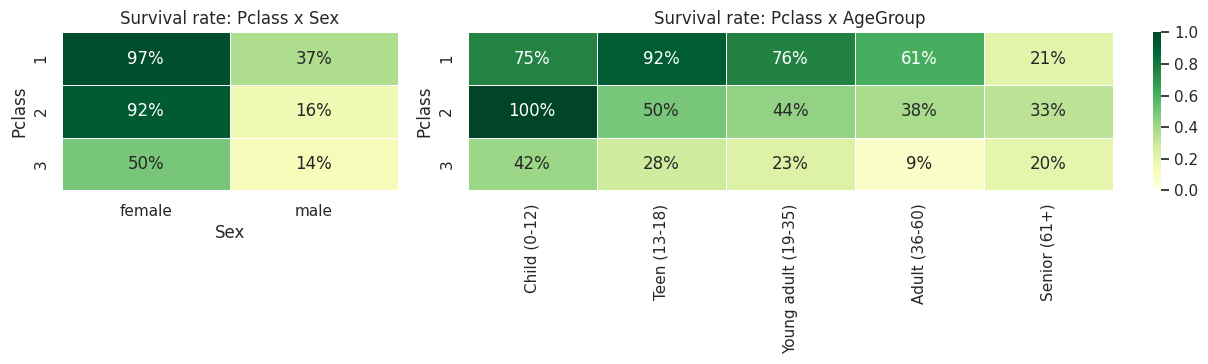

AgeGroup  Child (0-12)  Teen (13-18)  Young adult (19-35)  Adult (36-60)  \
Pclass                                                                     
1                    4            12                   66             90   
2                   17            12                   94             47   
3                   48            46                  198             58   

AgeGroup  Senior (61+)  
Pclass                  
1                   14  
2                    3  
3                    5  


In [25]:
pt_sex = df.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean")
pt_age = df.pivot_table(index="Pclass", columns="AgeGroup", values="Survived", aggfunc="mean", observed=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 2.4]})
sns.heatmap(pt_sex, annot=True, fmt=".0%", cmap="YlGn", vmin=0, vmax=1, linewidths=0.5, cbar=False, ax=axes[0])
axes[0].set_title("Survival rate: Pclass x Sex")
sns.heatmap(pt_age, annot=True, fmt=".0%", cmap="YlGn", vmin=0, vmax=1, linewidths=0.5, ax=axes[1])
axes[1].set_title("Survival rate: Pclass x AgeGroup"); axes[1].set_xlabel("")
plt.tight_layout()
save("16_survival_heatmaps")
print(df.pivot_table(index="Pclass", columns="AgeGroup", values="Survived", aggfunc="count", observed=True))

## 7. Statistical checks

In [26]:
rows = []
for col in ["Sex", "Pclass", "Embarked"]:
    ct = pd.crosstab(df[col], df["Survived"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append({"feature": col, "chi2": round(chi2, 1), "dof": dof, "p_value": f"{p:.2e}", "cramers_v": round(v, 3)})
display(pd.DataFrame(rows))

u_fare = stats.mannwhitneyu(df.loc[df.Survived == 1, "Fare"], df.loc[df.Survived == 0, "Fare"])
known = df.dropna(subset=["Age"])
u_age = stats.mannwhitneyu(known.loc[known.Survived == 1, "Age"], known.loc[known.Survived == 0, "Age"])
print(f"Mann-Whitney U  Fare by Survived: p = {u_fare.pvalue:.2e}")
print(f"Mann-Whitney U  Age  by Survived: p = {u_age.pvalue:.3f}")

# Multicollinearity: VIF = diagonal of the inverse correlation matrix
X = df[["Pclass", "Age", "SibSp", "Parch", "Fare"]].dropna()
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(X.values, rowvar=False))), index=X.columns, name="VIF").round(2)
print("\nVIF (raw numeric features):\n", vif.to_string())

X2 = df[["Pclass", "Age", "SibSp", "Parch", "FamilySize", "Fare"]].dropna()
cond = np.linalg.cond(np.corrcoef(X2.values, rowvar=False))
print(f"\nCondition number of the correlation matrix WITH FamilySize: {cond:.2e}  (huge -> redundant feature)")

,feature,chi2,dof,p_value,cramers_v
0,Sex,260.7,1,1.20e-58,0.541
1,Pclass,102.9,2,4.55e-23,0.340
2,Embarked,26.0,2,2.30e-06,0.171


Mann-Whitney U  Fare by Survived: p = 4.55e-22
Mann-Whitney U  Age  by Survived: p = 0.160

VIF (raw numeric features):
 Pclass    1.71
Age       1.29
SibSp     1.27
Parch     1.23
Fare      1.58

Condition number of the correlation matrix WITH FamilySize: 6.19e+14  (huge -> redundant feature)


## 8. Anomalies

In [27]:
zero = df[df["Fare"] == 0]
print(f"Fare = 0: {len(zero)} passengers | sex: {zero['Sex'].value_counts().to_dict()} | class: {zero['Pclass'].value_counts().sort_index().to_dict()} | survived: {zero['Survived'].sum()}")
top = df[df["Fare"] > 500]
print(f"Fare > 500: {len(top)} passengers | survived: {top['Survived'].sum()}")
print(f"Age < 1: {(df['Age'] < 1).sum()} passengers | survived: {df.loc[df['Age'] < 1, 'Survived'].sum()}")
old = df[df["Age"] >= 70]
print(f"Age >= 70: {len(old)} passengers | survived: {old['Survived'].sum()}")
big_fam = df[df["FamilySize"] == 11]
print(f"FamilySize = 11: {len(big_fam)} passengers | survived: {big_fam['Survived'].sum()}")
print(f"Passengers sharing a ticket number with someone else: {df['Ticket'].duplicated(keep=False).sum()}")

Fare = 0: 15 passengers | sex: {'male': 15} | class: {1: 5, 2: 6, 3: 4} | survived: 1
Fare > 500: 3 passengers | survived: 3
Age < 1: 7 passengers | survived: 7
Age >= 70: 7 passengers | survived: 1
FamilySize = 11: 7 passengers | survived: 0
Passengers sharing a ticket number with someone else: 344


## 9. Summary of findings

1. **Overall**: 342 of 891 passengers survived (38.4%).
2. **Sex was the dominant factor**: 74.2% of women vs 18.9% of men survived; the pattern holds inside every class.
3. **Class mattered strongly**: 63.0% / 47.3% / 24.2% survival for 1st / 2nd / 3rd class. Fare, cabin availability and age all follow the same class ladder, so they overlap with Pclass.
4. **Women and children first is visible**: children aged 0-12 survived at 58.0%, and boys (Master) at 57.5% vs 15.7% for adult men.
5. **Family context**: passengers travelling alone (30.4%) and in large families of 5+ (16.1%) did worse than those in families of 2-4 (55-72%).
6. **Interactions are key**: 3rd-class women (50.0%) survived more often than 1st-class men (36.9%); 3rd-class adults had only 9% survival.
7. **Port of embarkation** shows differences (Cherbourg 55.4% vs Southampton 33.9%), but largely because of the class mix of each port.
8. **Data quality**: Cabin is 77% missing, Age 20% missing (not at random), Fare is heavily skewed (4.79 -> 0.39 after log transform) and there are 15 zero-fare passengers.
9. **Next steps for modelling**: use Sex, Pclass, Title, FamilySize, LogFare and HasCabin; impute Age by Pclass/Sex medians (or Title); keep only one of FamilySize or SibSp/Parch; try logistic regression and a decision tree as baselines.

## 10. Interview questions

**1. What is EDA and why is it important?**

Exploratory Data Analysis is the process of summarising and visualising a dataset to understand its structure, quality, patterns, relationships and anomalies before modelling. It catches missing values, outliers and wrong data types early, guides feature engineering and the choice of model, and prevents building on false assumptions. In this project EDA revealed that sex and class dominate survival, that Fare needs a log transform and that Cabin is too sparse to use directly.

**2. Which plots do you use to check correlation?**

A correlation heatmap for all numeric pairs at a glance; scatterplots (or regplot/jointplot) for a specific pair; pairplot for all pairs plus distributions. For numeric vs categorical use boxplots/violin plots; for two categorical variables use grouped bars, crosstabs and a chi-square test.

**3. How do you handle skewed data?**

First measure it (skewness, histogram). Then apply a transform such as log / log1p, square root, Box-Cox or Yeo-Johnson; cap extreme values (winsorising); use robust statistics like the median/IQR; or use tree-based models that do not care about skew. Example here: Fare skewness 4.79 became 0.39 after log1p.

**4. How to detect multicollinearity?**

Look at the correlation matrix/heatmap (|r| above about 0.8 is a warning), compute the Variance Inflation Factor (VIF above 5-10 is a concern) and check the condition number. Fix it by dropping or combining features, using PCA, or regularisation (Ridge/Lasso). Example here: FamilySize is an exact sum of SibSp and Parch (r = 0.89 and 0.78).

**5. What are univariate, bivariate and multivariate analyses?**

Univariate looks at one variable at a time (histogram of Age, countplot of Sex). Bivariate looks at the relationship between two variables (survival rate by Sex, Fare by Pclass). Multivariate looks at three or more together (pairplot, correlation heatmap, survival by Pclass x Sex x AgeGroup).

**6. Difference between heatmap and pairplot?**

A heatmap is a colour-coded matrix of values, usually the correlation coefficients (or a pivot table), so it is compact and quantifies only linear strength. A pairplot is a grid of scatterplots plus distributions for every pair of variables, so it shows shape, clusters, outliers and group separation, but gets crowded and slow with many variables. Use the heatmap to screen, the pairplot to inspect.

**7. How do you summarise your insights?**

Lead with the finding, back it with a number and a visual, explain why it matters, state caveats (sample size, confounding, missing data) and end with a recommendation. Example: 'Women survived at 74% vs 19% for men, and the gap holds in every class; sex and class should be the core model features.'